# 🏆 08. PageRank & Phân tích Vai trò Tướng (Core Carry vs Flex Support)

**Thành viên thực hiện:** Thành viên 2 (Graph Mining Lead)

Mục tiêu:
- Ứng dụng **PageRank** trên đồ thị liên kết tướng để xếp hạng tầm quan trọng của từng nhân vật.
- Đối chiếu PageRank với Win-rate đơn thuần để phân loại: Core Carry, Flex Support, Overrated, Hidden Gem.
- Xác định nhân vật hạt nhân của từng Archetype đã tìm được ở bước phân cụm.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from src.graph_miner import GraphMiner
import warnings
warnings.filterwarnings('ignore')

## 1. Nạp dữ liệu và Đồ thị

In [2]:
cooc_wr = pd.read_pickle('../data/processed/cooc_winrate.pkl')
df_processed = pd.read_csv('../data/processed/tft_processed.csv')
gm = GraphMiner()
G = gm.build_network(cooc_wr, min_weight=0.15)

📊 Network: 107 nodes, 3187 edges, density=0.5620


## 2. Tính toán PageRank với các Damping Factor khác nhau

In [3]:
pr_85, ranking_85 = gm.compute_pagerank(G, alpha=0.85)
pr_50, _ = gm.compute_pagerank(G, alpha=0.50)
pr_95, _ = gm.compute_pagerank(G, alpha=0.95)

pr_compare = pd.DataFrame({
    'alpha_0.50': pr_50,
    'alpha_0.85': pr_85,
    'alpha_0.95': pr_95
})
pr_compare.sort_values(by='alpha_0.85', ascending=False).head(15)

🏆 PageRank Top 5 (α=0.85):
   Soraka: 0.0163
   Thresh: 0.0160
   MasterYi: 0.0157
   Ashe: 0.0155
   Karma: 0.0149
🏆 PageRank Top 5 (α=0.5):
   Soraka: 0.0136
   Thresh: 0.0135
   MasterYi: 0.0132
   Ashe: 0.0131
   Karma: 0.0128
🏆 PageRank Top 5 (α=0.95):
   Soraka: 0.0170
   Thresh: 0.0166
   MasterYi: 0.0164
   Ashe: 0.0161
   Karma: 0.0154


,alpha_0.50,alpha_0.85,alpha_0.95
Soraka,0.013625,0.016312,0.016990
Thresh,0.013489,0.016011,0.016605
MasterYi,0.013217,0.015707,0.016423
Ashe,0.013126,0.015470,0.016075
Karma,0.012771,0.014881,0.015398
Ezreal,0.012573,0.014615,0.015156
Malphite,0.012524,0.014536,0.015076
Annie,0.012404,0.014331,0.014837
Syndra,0.012349,0.014216,0.014694
Nami,0.011770,0.013687,0.014419


## 3. Đối chiếu PageRank vs Win-rate (Ma trận 4 góc chiến thuật)

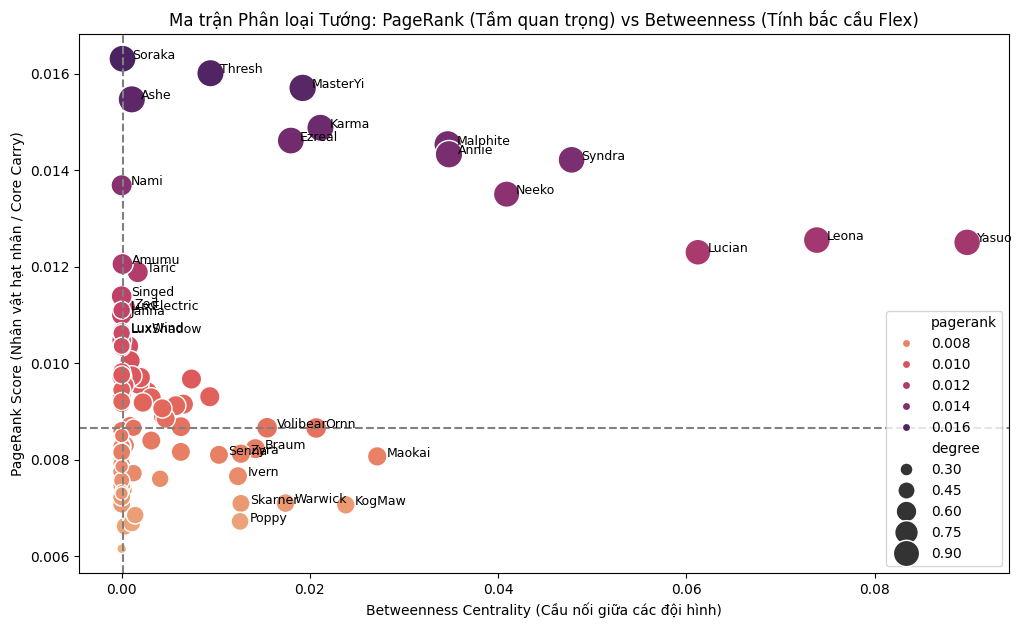

In [4]:
centrality = gm.compute_centrality_metrics(G)
centrality['pagerank'] = centrality.index.map(pr_85)

# Trực quan hóa ma trận PageRank vs Betweenness Centrality
fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(data=centrality, x='betweenness', y='pagerank', size='degree', sizes=(50, 400), hue='pagerank', palette='flare', ax=ax)

median_bet = centrality['betweenness'].median()
median_pr = centrality['pagerank'].median()
ax.axvline(median_bet, color='gray', linestyle='--')
ax.axhline(median_pr, color='gray', linestyle='--')

for node, row in centrality.iterrows():
    if row['pagerank'] > centrality['pagerank'].quantile(0.8) or row['betweenness'] > centrality['betweenness'].quantile(0.8):
        ax.text(row['betweenness'] + 0.001, row['pagerank'], node, fontsize=9)

ax.set_title('Ma trận Phân loại Tướng: PageRank (Tầm quan trọng) vs Betweenness (Tính bắc cầu Flex)')
ax.set_xlabel('Betweenness Centrality (Cầu nối giữa các đội hình)')
ax.set_ylabel('PageRank Score (Nhân vật hạt nhân / Core Carry)')
plt.show()

## 4. Xác định Core Carry của từng Đội hình

In [5]:
part_louvain, _, _ = gm.detect_communities_louvain(G)
from src.champion_metadata import CHAMPIONS_SET3 as CHAMPIONS
archetypes = gm.identify_meta_archetypes(G, part_louvain, champion_data=CHAMPIONS)
display(archetypes[['community', 'archetype', 'core_champion', 'core_pagerank', 'size']])

🔵 Louvain (res=1.0): 2 communities, modularity=0.3026


,community,archetype,core_champion,core_pagerank,size
0,0,Rebel + Battlecast,MasterYi,0.0164,59
1,1,StarGuardian + Sorcerer,Soraka,0.0170,48


## 5. Kết luận PageRank
- **PageRank cao + Betweenness thấp**: Tướng Core Carry chuyên biệt (Carry gánh team của 1 đội hình cụ thể).
- **PageRank cao + Betweenness cao**: Tướng Flex quốc dân (vừa mạnh vừa ghép được vào nhiều đội hình).